# 05 — Model evaluation

In [ ]:
from src.pipeline import run_experiments\ncomparison, test_metrics, best_model = run_experiments()\ncomparison

Analyse false positives and false negatives. Use validation for model selection; keep test for final evaluation.

In [ ]:
from pathlib import Path
import os

# Si Jupyter travaille depuis le dossier notebooks,
# remonter à la racine du projet.
if Path.cwd().name == "notebooks":
    os.chdir("..")

print("Dossier de travail :", Path.cwd())
print("Dossier src trouvé :", Path("src").is_dir())
print("Données trouvées :", Path("data/raw/train_text.txt").is_file())

Dossier de travail : c:\Users\USER\Desktop\Project Ml\TweetEval-Offensive-ML
Dossier src trouvé : True
Données trouvées : True


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import os
print(os.getcwd())
import os
os.chdir("..")

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from src.data_loader import load_dataset
from src.preprocessing import clean_texts
from src.models import get_models
from src.pipeline import make_pipeline
from src.evaluation import calculate_metrics, get_confusion_matrix

c:\Users\USER\Desktop\Project Ml\TweetEval-Offensive-ML\notebooks


In [8]:
# Charger les jeux officiels
donnees = load_dataset(data_dir="data/raw")

train = donnees["train"]
val = donnees["validation"]

# Appliquer le nettoyage défini dans le projet
X_train = clean_texts(train["text"].tolist())
y_train = train["label"]

X_val = clean_texts(val["text"].tolist())
y_val = val["label"]

print("Tweets d'entraînement :", len(X_train))
print("Tweets de validation  :", len(X_val))

Tweets d'entraînement : 11916
Tweets de validation  : 1324


In [9]:
# Récupérer les modèles définis dans src/models.py
modeles = get_models()

# Ajouter KNN s'il n'est pas encore présent dans le projet
if not any("knn" in nom.lower() for nom in modeles):
    modeles["KNN"] = KNeighborsClassifier(n_neighbors=5)

print("Modèles à évaluer :")
for nom in modeles:
    print("-", nom)

Modèles à évaluer :
- Naive Bayes
- Logistic Regression
- Linear SVM
- Random Forest
- KNN


In [10]:
resultats = []
modeles_entraines = {}
predictions_validation = {}

for nom, classifieur in modeles.items():
    print(f"Entraînement : {nom}...")

    # La pipeline apprend TF-IDF uniquement sur les données train
    modele = make_pipeline(classifieur)
    modele.fit(X_train, y_train)

    # Prédictions sur la validation
    y_pred = modele.predict(X_val)

    # Calculer les scores
    scores = calculate_metrics(y_val, y_pred)
    resultats.append({"modele": nom, **scores})

    # Conserver les modèles et prédictions pour la suite
    modeles_entraines[nom] = modele
    predictions_validation[nom] = y_pred

tableau = pd.DataFrame(resultats)
tableau = tableau.sort_values("f1", ascending=False).reset_index(drop=True)

print("Comparaison sur le jeu de validation :")
display(tableau.round(3))

Entraînement : Naive Bayes...
Entraînement : Logistic Regression...
Entraînement : Linear SVM...
Entraînement : Random Forest...
Entraînement : KNN...
Comparaison sur le jeu de validation :


,modele,accuracy,precision,recall,f1
0,Logistic Regression,0.720,0.592,0.614,0.603
1,Linear SVM,0.712,0.582,0.601,0.592
2,Random Forest,0.739,0.697,0.436,0.536
3,Naive Bayes,0.715,0.880,0.207,0.335
4,KNN,0.683,0.636,0.198,0.302


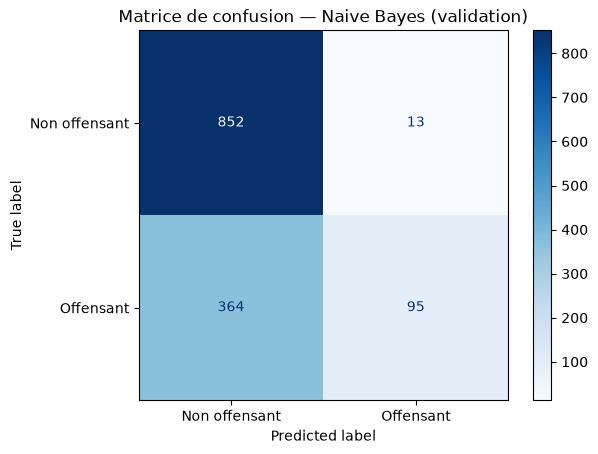

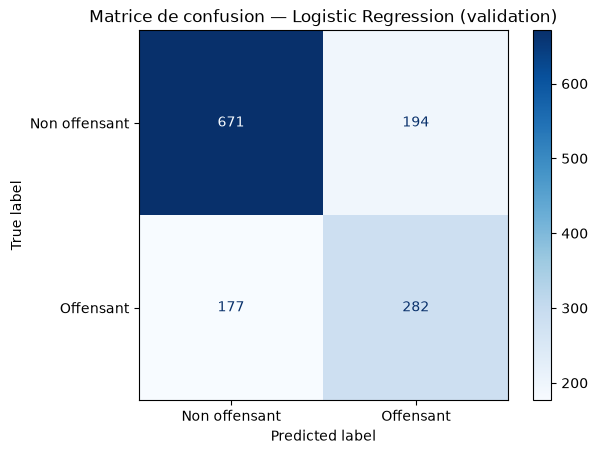

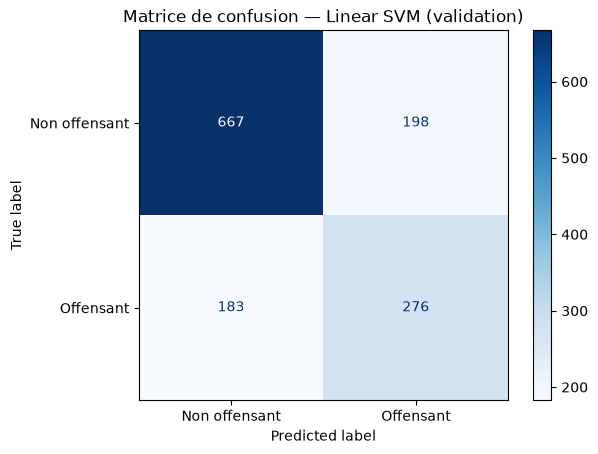

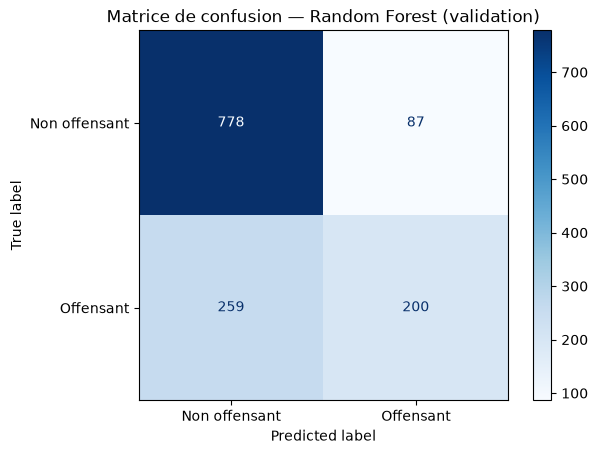

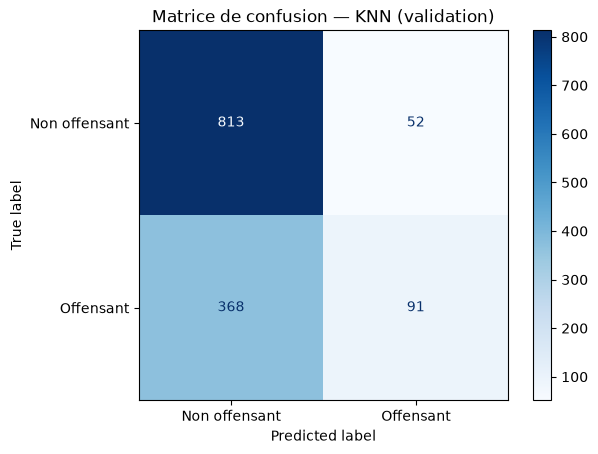

In [11]:
for nom, y_pred in predictions_validation.items():
    matrice = get_confusion_matrix(y_val, y_pred)

    affichage = ConfusionMatrixDisplay(
        confusion_matrix=matrice,
        display_labels=["Non offensant", "Offensant"]
    )

    affichage.plot(cmap="Blues", values_format="d")
    plt.title(f"Matrice de confusion — {nom} (validation)")
    plt.show()

In [12]:
from pathlib import Path

dossier_resultats = Path("results/metrics")
dossier_resultats.mkdir(parents=True, exist_ok=True)

tableau.to_csv(
    dossier_resultats / "validation_model_comparison.csv",
    index=False
)

print("Tableau enregistré dans results/metrics/")

Tableau enregistré dans results/metrics/


In [13]:
matrice_lr = get_confusion_matrix(
    y_val,
    predictions_validation["Logistic Regression"]
)

display(pd.DataFrame(
    matrice_lr,
    index=["Réel : non offensant", "Réel : offensant"],
    columns=["Prédit : non offensant", "Prédit : offensant"]
))

,Prédit : non offensant,Prédit : offensant
Réel : non offensant,671,194
Réel : offensant,177,282


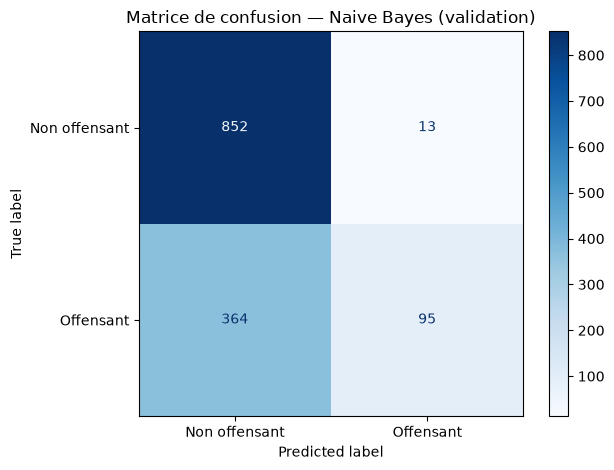

Figure enregistrée : results\figures\confusion_validation_naive_bayes.png


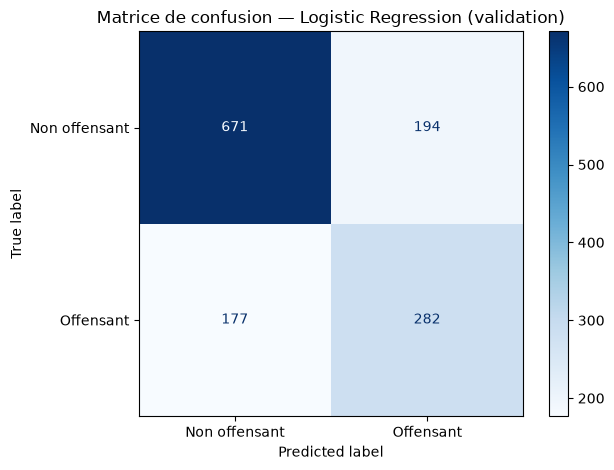

Figure enregistrée : results\figures\confusion_validation_logistic_regression.png


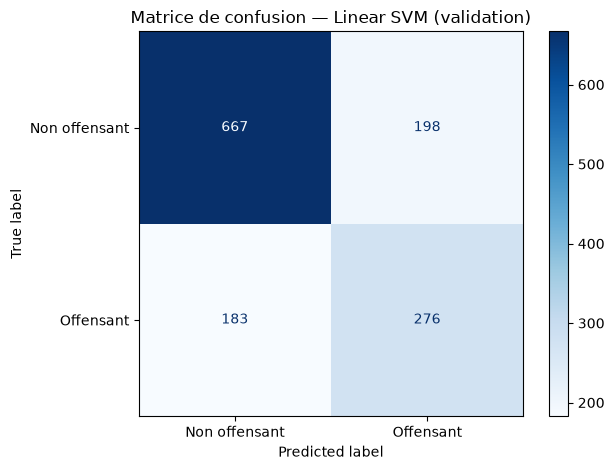

Figure enregistrée : results\figures\confusion_validation_linear_svm.png


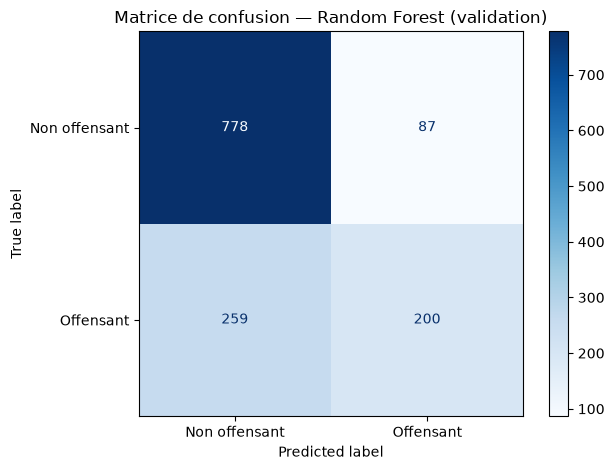

Figure enregistrée : results\figures\confusion_validation_random_forest.png


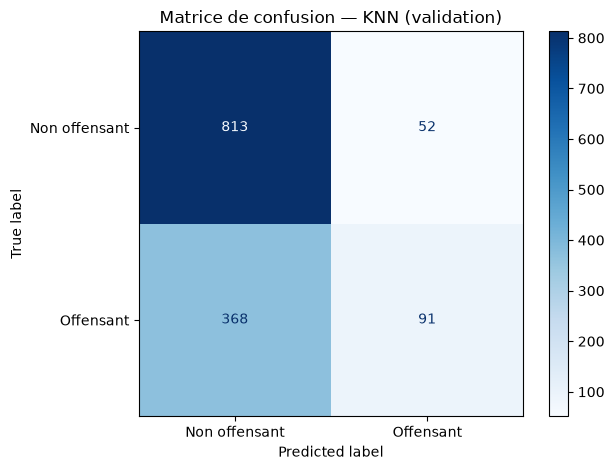

Figure enregistrée : results\figures\confusion_validation_knn.png


In [14]:
from pathlib import Path

dossier_figures = Path("results/figures")
dossier_figures.mkdir(parents=True, exist_ok=True)

for nom, y_pred in predictions_validation.items():
    matrice = get_confusion_matrix(y_val, y_pred)

    affichage = ConfusionMatrixDisplay(
        confusion_matrix=matrice,
        display_labels=["Non offensant", "Offensant"]
    )

    affichage.plot(cmap="Blues", values_format="d")
    plt.title(f"Matrice de confusion — {nom} (validation)")
    plt.tight_layout()

    # Créer un nom de fichier simple
    nom_fichier = nom.lower().replace(" ", "_")
    chemin = dossier_figures / f"confusion_validation_{nom_fichier}.png"

    plt.savefig(chemin, dpi=150)
    plt.show()

    print(f"Figure enregistrée : {chemin}")

In [15]:
chemin_tableau = Path("results/metrics/validation_model_comparison.csv")
print("Tableau enregistré :", chemin_tableau.is_file())

Tableau enregistré : True
